In [14]:
import pandas as pd
dtset = pd.read_csv("processedPlacementData.csv")
dtset.isnull().sum()
quan = dtset.select_dtypes(include=['number'])

In [15]:
# Quantitative columns
covar = dtset.select_dtypes(include=['number']).cov()

covar

,ssc_p,hsc_p,degree_p,etest_p,mba_p,salary
ssc_p,117.228377,60.348373,42.897137,37.659225,24.535952,1.976764e+04
hsc_p,60.348373,118.755706,34.819820,35.461678,22.555846,4.600806e+04
degree_p,42.897137,34.819820,54.151103,21.929469,17.272020,-8.064357e+03
etest_p,37.659225,35.461678,21.929469,176.251018,16.886973,1.571579e+05
mba_p,24.535952,22.555846,17.272020,16.886973,34.028376,6.611551e+04
salary,19767.643976,46008.057275,-8064.357161,157157.850783,66115.509283,5.999726e+09


In [16]:
corrl = dtset.select_dtypes(include=['number']).corr()
corrl

,ssc_p,hsc_p,degree_p,etest_p,mba_p,salary
ssc_p,1.000000,0.511472,0.538404,0.261993,0.388478,0.023571
hsc_p,0.511472,1.000000,0.434206,0.245113,0.354823,0.054506
degree_p,0.538404,0.434206,1.000000,0.224470,0.402364,-0.014148
etest_p,0.261993,0.245113,0.224470,1.000000,0.218055,0.152829
mba_p,0.388478,0.354823,0.402364,0.218055,1.000000,0.146324
salary,0.023571,0.054506,-0.014148,0.152829,0.146324,1.000000


In [19]:
corwith = quan.corrwith(quan['mba_p'])
corwith

ssc_p       0.388478
hsc_p       0.354823
degree_p    0.402364
etest_p     0.218055
mba_p       1.000000
salary      0.146324
dtype: float64

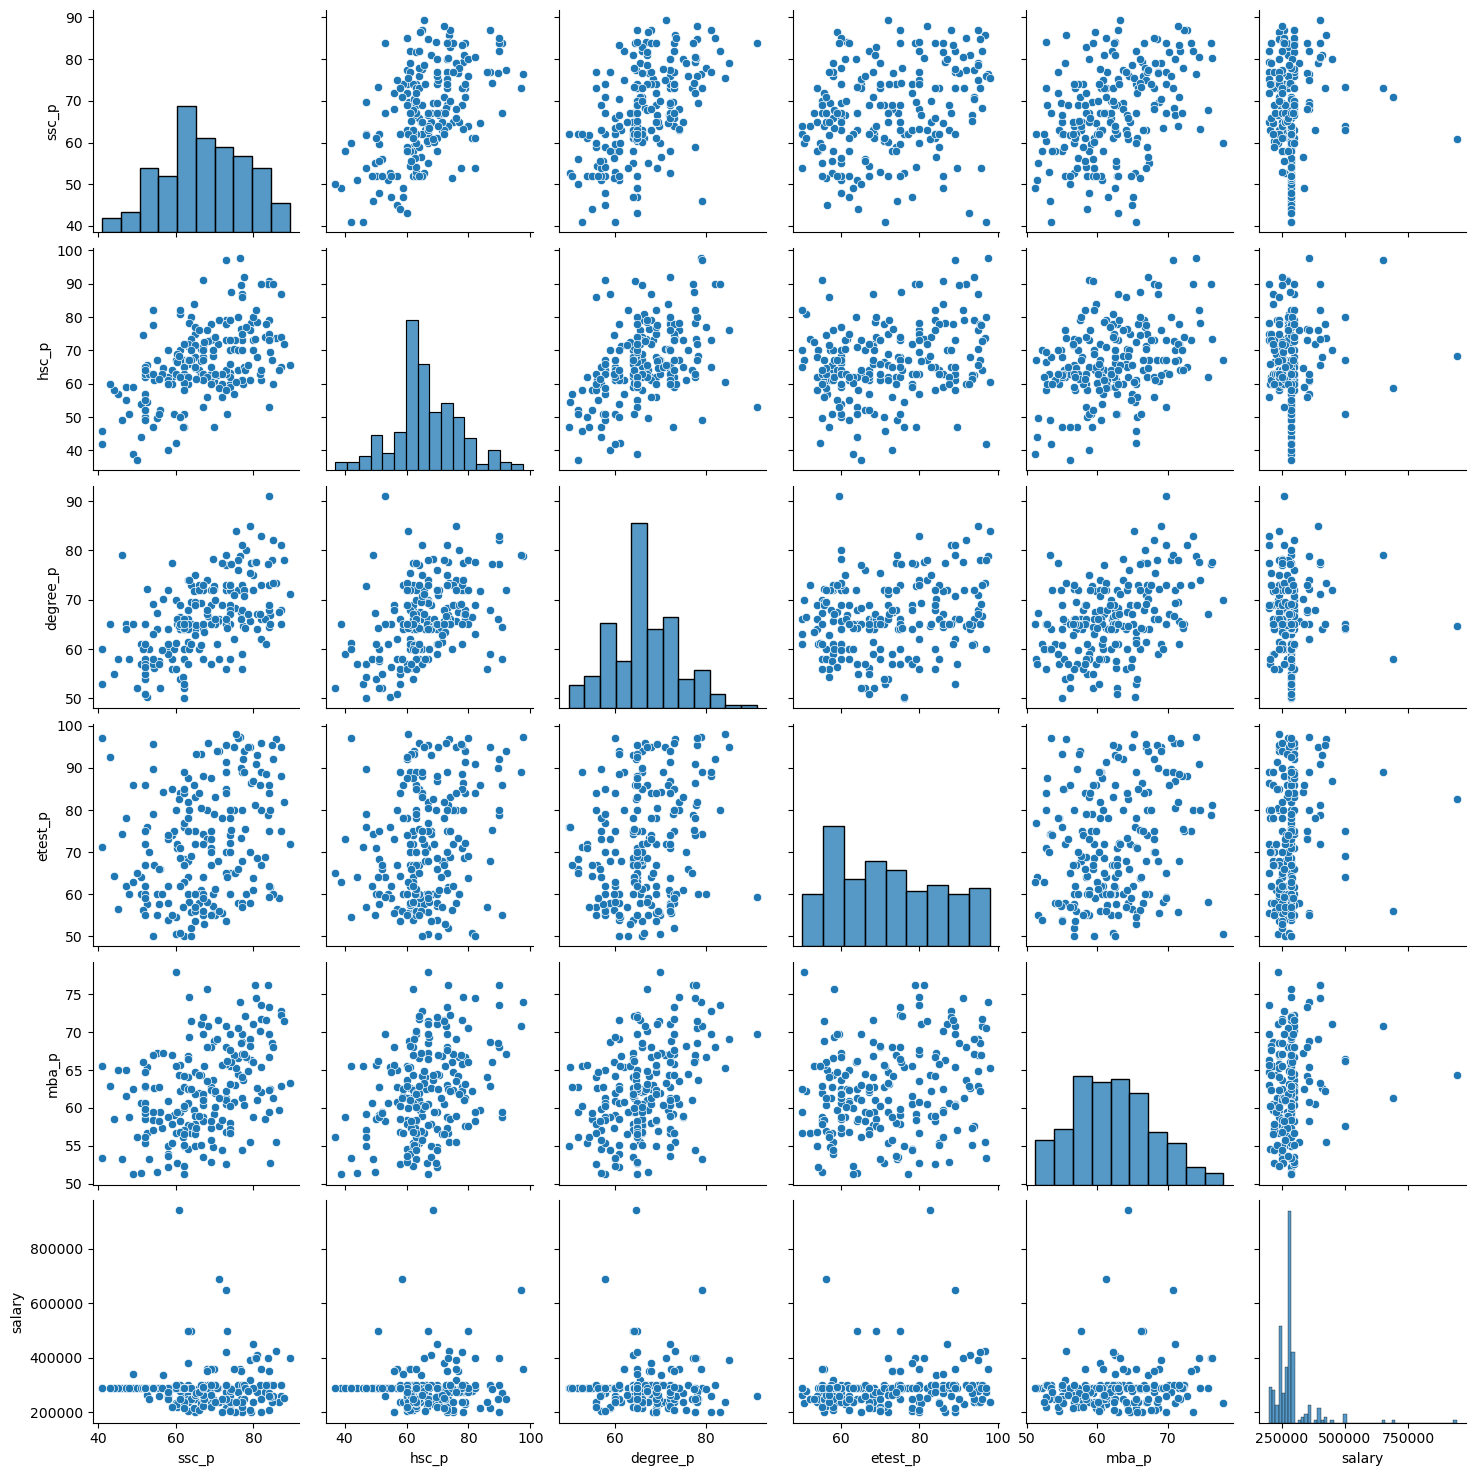

In [14]:
import seaborn as sn
sn.pairplot(dtset)

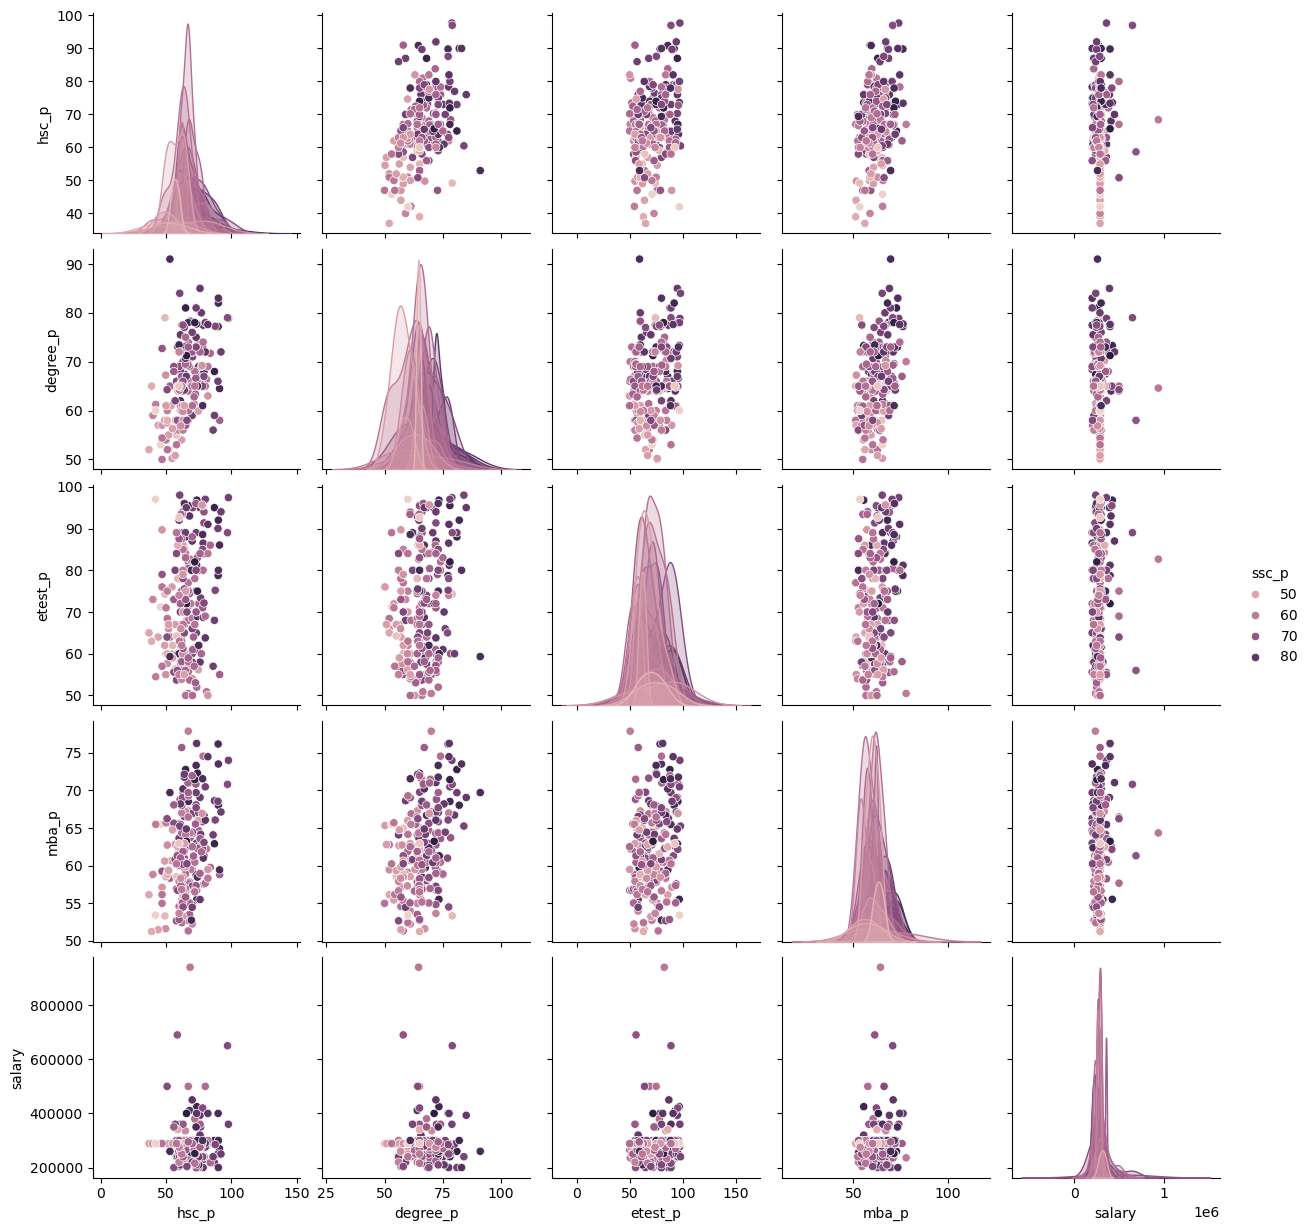

In [24]:
import seaborn as sn
sn.pairplot(dtset,hue='ssc_p')

#save image
import matplotlib.pyplot as plt
plt.savefig("ssc__p_pair.jpg")

In [22]:
#VIP
from statsmodels.stats.outliers_influence import variance_inflation_factor

def calculate_VIF(dtset):
    vif = pd.DataFrame()
    vif["dtCols"] = dtset.columns
    vif["colVIF"] = [variance_inflation_factor(dtset.values, i) for i in range (dtset.shape[1])]
    return vif

dtQuan = dtset.select_dtypes(include=['number']).dropna()

calculate_VIF(dtQuan)
    


,dtCols,colVIF
0,ssc_p,67.026700
1,hsc_p,56.131492
2,degree_p,112.755275
3,etest_p,33.696391
4,mba_p,108.585463
5,salary,15.167704


In [27]:
calculate_VIF(dtset[["hsc_p","mba_p"]])

,dtCols,colVIF
0,hsc_p,41.545696
1,mba_p,41.545696


In [4]:
#paired test
from scipy.stats import ttest_ind
fmale = dtset[dtset['gender']=='F']['salary']
male = dtset[dtset['gender']=='M']['salary']
ttest_ind(male,fmale)

TtestResult(statistic=np.float64(1.9001627265152634), pvalue=np.float64(0.05876239427122642), df=np.float64(213.0))

In [8]:
#un paired test
from scipy.stats import ttest_rel
male1 = dtset[dtset['gender']=='M']['ssc_p']
male2 = dtset[dtset['gender']=='M']['hsc_p']
ttest_rel(male1,male2)

TtestResult(statistic=np.float64(0.6852881050898076), pvalue=np.float64(0.49431164600731514), df=np.int64(138))

In [13]:
#ANAVO
import scipy.stats as sts
result = sts.f_oneway(dtset['ssc_p'], dtset['hsc_p'], dtset['degree_p'])
print (result.pvalue)
print(result.statistic)

0.5110602818995302
0.6719700864663097


In [25]:
import statsmodels.api as sm
from statsmodels.formula.api import ols

#perform two-way ANOVA
model = ols(
    'degree_p ~ ssc_p + hsc_p + ssc_p:hsc_p',
    data=dtset
).fit()

sm.stats.anova_lm(model, typ=2)

,sum_sq,df,F,PR(>F)
ssc_p,1570.306565,1.0,42.434218,5.269427e-10
hsc_p,395.896104,1.0,10.698256,1.252482e-03
ssc_p:hsc_p,25.030257,1.0,0.676390,4.117611e-01
Residual,7808.195933,211.0,NaN,NaN
